# 01 · Datos, etiquetas y análisis exploratorio

En este notebook:
1. Cargamos los datos de CORDIS (`projects.xlsx`) y la jerarquía EuroSciVoc (`SciVocCodes.xlsx`).
2. Construimos la variable objetivo (nivel 2 de EuroSciVoc) siguiendo la sección 3 del enunciado.
3. Hacemos la partición train/val/test que usará todo el equipo.
4. Análisis exploratorio.

In [2]:
import os
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# En Colab los ficheros subidos están en /content/; en local, en la carpeta data/
if os.path.exists("/content"):
    RUTA_DATOS = "/content/"
    RUTA_RESULTADOS = "/content/"
    RUTA_FIGURAS = "/content/"
else:
    RUTA_DATOS = "../data/"
    RUTA_RESULTADOS = "../resultados/"
    RUTA_FIGURAS = "../figuras/"

## 1. Carga de los datos

In [3]:
proyectos = pd.read_excel(RUTA_DATOS + "projects.xlsx")
scivoc = pd.read_excel(RUTA_DATOS + "SciVocCodes.xlsx")

print("Proyectos:", proyectos.shape)
print("Términos EuroSciVoc:", scivoc.shape)

Proyectos: (35378, 19)
Términos EuroSciVoc: (1013, 4)


In [4]:
# La columna euroSciVocCode viene como texto, por ejemplo "[155, 56306972, 325]"
proyectos[["projectID", "title", "euroSciVocCode"]].head()

,projectID,title,euroSciVocCode
0,115843,Ebola Virus: Modern Approaches for developing ...,"[155, 56306972, 325, 137, 1609]"
1,115910,PERtussIS COrrelates of Protection Europe - So...,"[137, 1439, 44109686, 48479582]"
2,635266,Opening the cycling and walking tracking poten...,[1373]
3,637488,"Motivating Motor Learning: The Role of Reward,...","[159, 227, 337, 635]"
4,639226,The Power of Maternal Microbes on Infant Health,"[155, 137, 38005658, 1461, 183]"


In [5]:
# Cada término de la jerarquía tiene su camino completo desde la raíz en full_code
scivoc[["code", "full_code", "full_path"]].head()

,code,full_code,full_path
0,NaN,/27/79/483/,/agricultural sciences/agricultural biotechnol...
1,1275.0,/27/79/483/1275,/agricultural sciences/agricultural biotechnol...
2,483.0,/27/79/483,/agricultural sciences/agricultural biotechnol...
3,481.0,/27/79/481,/agricultural sciences/agricultural biotechnol...
4,487.0,/27/79/487,/agricultural sciences/agricultural biotechnol...


## 2. Construcción de la etiqueta

Cada proyecto tiene una lista de códigos EuroSciVoc. Para cada código, `full_code` nos da el camino
desde la raíz, por ejemplo `/21/35/155`:

- el **primer** número es la categoría de **nivel 1** (21 = *medical and health sciences*),
- el **segundo** número es la categoría de **nivel 2** (35 = *basic medicine*).

Así que "subir por la jerarquía hasta el nivel 2" entendemos que es quedarnos con el segundo elemento del camino.

En el enunciado nos piden que:
1. Se recorren los códigos **en orden** y nos quedamos con el **primero** que tenga nivel 2.
2. Los códigos que no lleguen al nivel 2 los ignoramos.
3. Si ningún código del proyecto vale, el proyecto se descarta.

Además guardamos las otras categorías de nivel 2 del proyecto (**descartadas**), porque nos servirán
en el análisis de errores: si el modelo predice una de ellas, no es un fallo "real".

In [6]:
# Quitamos las 3 filas de SciVocCodes que no tienen código
scivoc = scivoc.dropna(subset=["code"])
scivoc["code"] = scivoc["code"].astype(int)

# Diccionarios para buscar rápido: código -> camino y código -> nombre
camino = dict(zip(scivoc["code"], scivoc["full_code"]))
nombre = dict(zip(scivoc["code"].astype(str), scivoc["title"]))

In [7]:
def obtener_etiquetas(codigos_texto):
    """Devuelve (nivel1, nivel2, descartadas) de un proyecto, o None si no hay etiqueta válida."""
    if pd.isna(codigos_texto):          # proyecto sin códigos
        return None

    codigos = ast.literal_eval(codigos_texto)   # "[155, 325]" -> [155, 325]

    niveles2 = []   # categorías de nivel 2 de todos los códigos, en orden
    nivel1 = None
    for c in codigos:
        if c not in camino:             # código que no está en la jerarquía
            continue
        partes = [x for x in camino[c].split("/") if x != ""]   # "/21/35/155" -> ["21","35","155"]
        if len(partes) < 2:             # no llega al nivel 2
            continue
        if len(niveles2) == 0:          # el primer código válido da la etiqueta
            nivel1 = partes[0]
        niveles2.append(partes[1])

    if len(niveles2) == 0:
        return None

    nivel2 = niveles2[0]
    descartadas = sorted(set(niveles2) - {nivel2})
    return nivel1, nivel2, descartadas

In [8]:
# Comprobamos con el ejemplo del proyecto 115843
ejemplo = proyectos.loc[proyectos["projectID"] == 115843, "euroSciVocCode"].iloc[0]
n1, n2, desc = obtener_etiquetas(ejemplo)
print("Códigos:", ejemplo)
print("Nivel 1:", nombre[n1])
print("Nivel 2:", nombre[n2])
print("Descartadas:", [nombre[d] for d in desc])

Códigos: [155, 56306972, 325, 137, 1609]
Nivel 1: medical and health sciences
Nivel 2: basic medicine
Descartadas: ['health sciences', 'biological sciences']


In [9]:
etiquetas = proyectos["euroSciVocCode"].apply(obtener_etiquetas)

# Nos quedamos solo con los proyectos que tienen etiqueta válida
datos = proyectos[etiquetas.notna()].copy()
etiquetas = etiquetas[etiquetas.notna()]

datos["nivel1"] = [nombre[e[0]] for e in etiquetas]
datos["nivel2"] = [nombre[e[1]] for e in etiquetas]
datos["descartadas"] = [[nombre[d] for d in e[2]] for e in etiquetas]

print(f"Proyectos conservados: {len(datos)} de {len(proyectos)} "
      f"({100 * len(datos) / len(proyectos):.2f} %)  -> el enunciado dice aprox. 90,31 %")
print("Clases de nivel 2:", datos["nivel2"].nunique())
print("Clases de nivel 1:", datos["nivel1"].nunique())

Proyectos conservados: 31982 de 35378 (90.40 %)  -> el enunciado dice aprox. 90,31 %
Clases de nivel 2: 39
Clases de nivel 1: 6


In [10]:
# ¿Cuántos proyectos tienen todos sus códigos en la misma categoría de nivel 2?
inequivocos = (datos["descartadas"].apply(len) == 0).mean()
print(f"Proyectos sin categorías descartadas: {100 * inequivocos:.1f} %  -> el enunciado dice aprox. 32 %")

Proyectos sin categorías descartadas: 32.2 %  -> el enunciado dice aprox. 32 %


In [11]:
# Guardamos el resultado para los siguientes pasos (data/ no se sube a GitHub)
datos.to_pickle(RUTA_DATOS + "proyectos_etiquetados.pkl")

## 3. Partición train / validación / test

Hacemos **una única partición** que usará todo el equipo, para que todos los modelos se comparen
sobre exactamente los mismos proyectos.

- **70 % train**: para entrenar los modelos (y ajustar TF-IDF, Word2Vec, escaladores...).
- **15 % validación**: para elegir hiperparámetros y comparar configuraciones.
- **15 % test**: solo se usa **una vez al final**, para dar el resultado definitivo.

La partición es **estratificada** por la etiqueta de nivel 2: cada conjunto mantiene las mismas
proporciones de clases. Es importante porque las clases están muy desbalanceadas (la más pequeña,
*other medical sciences*, solo tiene 9 proyectos). Fijamos la semilla (`random_state=42`) para que
sea reproducible.

Para el nivel 1 usamos **la misma partición**: los proyectos son los mismos, solo cambia la etiqueta.

In [12]:
from sklearn.model_selection import train_test_split

# Primero separamos el 15 % de test
train_val, test = train_test_split(datos, test_size=0.15,
                                   stratify=datos["nivel2"], random_state=42)

# Del 85 % restante, separamos validación (0.15 / 0.85 del resto = 15 % del total)
train, val = train_test_split(train_val, test_size=0.15 / 0.85,
                              stratify=train_val["nivel2"], random_state=42)

print(f"Train: {len(train)}  ({100 * len(train) / len(datos):.1f} %)")
print(f"Val:   {len(val)}  ({100 * len(val) / len(datos):.1f} %)")
print(f"Test:  {len(test)}  ({100 * len(test) / len(datos):.1f} %)")

Train: 22386  (70.0 %)
Val:   4798  (15.0 %)
Test:  4798  (15.0 %)


In [13]:
# Comprobamos que la estratificación funciona: proporción de cada clase en cada conjunto
proporciones = pd.DataFrame({
    "train": train["nivel2"].value_counts(normalize=True),
    "val": val["nivel2"].value_counts(normalize=True),
    "test": test["nivel2"].value_counts(normalize=True),
}).round(3)
proporciones.head(10)

,train,val,test
nivel2,,,
agricultural biotechnology,0.001,0.001,0.001
"agriculture, forestry, and fisheries",0.014,0.014,0.014
animal and dairy science,0.004,0.004,0.004
arts,0.006,0.006,0.006
basic medicine,0.060,0.060,0.060
biological sciences,0.108,0.108,0.108
chemical engineering,0.004,0.004,0.004
chemical sciences,0.050,0.050,0.050
civil engineering,0.010,0.010,0.010


In [14]:
# Guardamos la partición: un CSV con el identificador de cada proyecto y su conjunto.
# Este fichero SÍ se sube a GitHub: todas lo leen en lugar de hacer su propia partición.
particion = pd.concat([
    pd.DataFrame({"projectID": train["projectID"], "conjunto": "train"}),
    pd.DataFrame({"projectID": val["projectID"], "conjunto": "val"}),
    pd.DataFrame({"projectID": test["projectID"], "conjunto": "test"}),
])
particion.to_csv(RUTA_RESULTADOS + "particion.csv", index=False)
particion["conjunto"].value_counts()

,count
conjunto,
train,22386
val,4798
test,4798


## 4. Análisis exploratorio

Todas las figuras se guardan en `figuras/` porque el README tiene que incluirlas
(el enunciado pide que el informe se pueda leer sin ejecutar el código).

### 4.1. Descripción general

In [15]:
# Variables del conjunto original: tipo y valores ausentes
descripcion = pd.DataFrame({
    "tipo": proyectos.dtypes.astype(str),
    "ausentes": proyectos.isna().sum(),
    "% ausentes": (100 * proyectos.isna().mean()).round(1),
})
print("Instancias:", len(proyectos), "  Variables:", proyectos.shape[1])
descripcion

Instancias: 35378   Variables: 19


,tipo,ausentes,% ausentes
projectID,int64,0,0.0
acronym,object,0,0.0
title,object,0,0.0
summary,object,0,0.0
startDate,datetime64[ns],11,0.0
endDate,datetime64[ns],11,0.0
totalCost,float64,0,0.0
ecMaxContribution,float64,0,0.0
masterCall,object,20358,57.5
subCall,object,0,0.0


Para clasificar solo usaremos el **texto** (`title` y `summary`), que no tiene ningún valor ausente.
Los ausentes de `euroSciVocCode` son justamente los proyectos que descartamos al construir la etiqueta.

### 4.2. Distribución de la variable objetivo

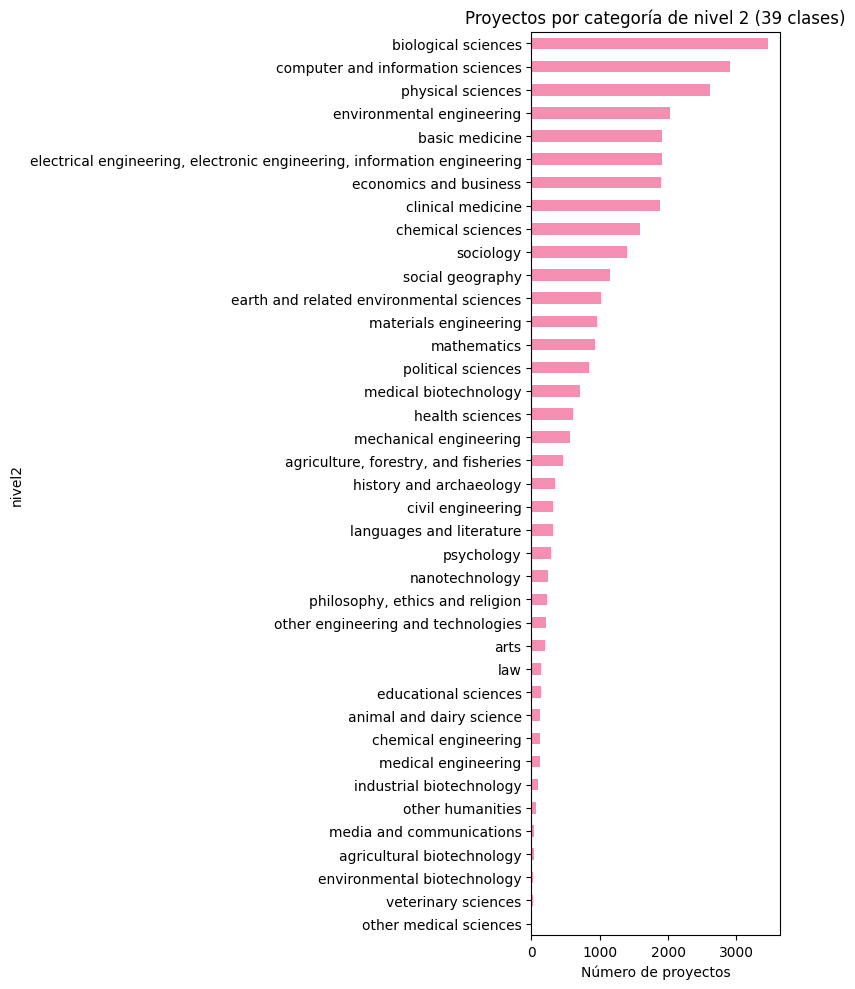

Clase mayor: biological sciences (3464 proyectos)
Clase menor: other medical sciences (9 proyectos)
Desbalance (mayor / menor): 385 veces


In [25]:
conteo2 = datos["nivel2"].value_counts()

plt.figure(figsize=(8, 10))
conteo2.sort_values().plot(kind="barh", color="#f48fb1")
plt.xlabel("Número de proyectos")
plt.title("Proyectos por categoría de nivel 2 (39 clases)")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "eda_clases_nivel2.png", dpi=120)
plt.show()

print(f"Clase mayor: {conteo2.index[0]} ({conteo2.iloc[0]} proyectos)")
print(f"Clase menor: {conteo2.index[-1]} ({conteo2.iloc[-1]} proyectos)")
print(f"Desbalance (mayor / menor): {conteo2.iloc[0] / conteo2.iloc[-1]:.0f} veces")

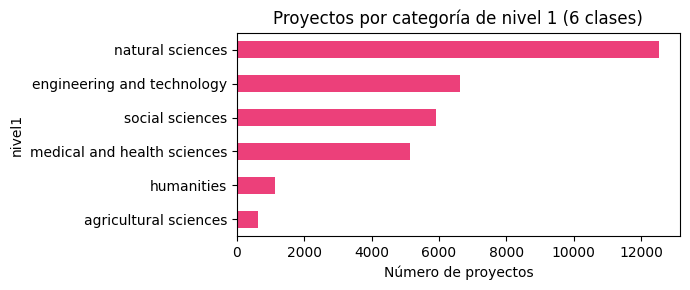

In [26]:
conteo1 = datos["nivel1"].value_counts()

plt.figure(figsize=(7, 3))
conteo1.sort_values().plot(kind="barh", color="#ec407a")
plt.xlabel("Número de proyectos")
plt.title("Proyectos por categoría de nivel 1 (6 clases)")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "eda_clases_nivel1.png", dpi=120)
plt.show()

**Modelo de referencia (baseline).** Un clasificador que siempre predice la clase más frecuente
en train. Es el mínimo que cualquier modelo tiene que superar. Con clases tan desbalanceadas,
su accuracy no es despreciable, pero su **macro-F1 es casi cero**: por eso la accuracy sola
no sirve para comparar modelos.

In [18]:
from sklearn.metrics import accuracy_score, f1_score

filas = []
for nivel in ["nivel2", "nivel1"]:
    clase_mayoritaria = train[nivel].value_counts().index[0]   # se calcula SOLO con train
    for nombre_conjunto, conjunto in [("val", val), ("test", test)]:
        y_true = conjunto[nivel]
        y_pred = [clase_mayoritaria] * len(conjunto)
        filas.append({
            "nivel": nivel,
            "conjunto": nombre_conjunto,
            "clase predicha": clase_mayoritaria,
            "accuracy": round(accuracy_score(y_true, y_pred), 3),
            "macro-F1": round(f1_score(y_true, y_pred, average="macro"), 3),
        })

baseline = pd.DataFrame(filas)
baseline.to_csv(RUTA_RESULTADOS + "baseline.csv", index=False)
baseline

,nivel,conjunto,clase predicha,accuracy,macro-F1
0,nivel2,val,biological sciences,0.108,0.005
1,nivel2,test,biological sciences,0.108,0.005
2,nivel1,val,natural sciences,0.392,0.094
3,nivel1,test,natural sciences,0.392,0.094


### 4.3. Estadísticas básicas

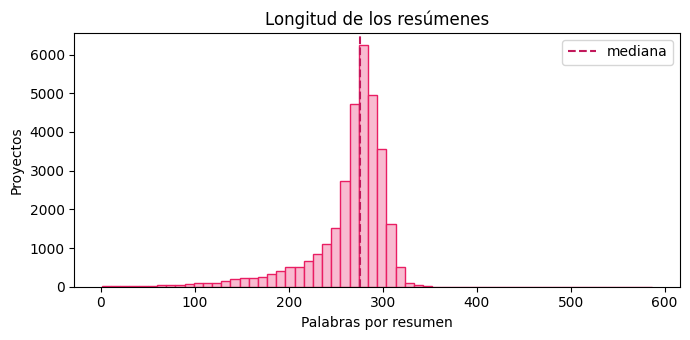

count    31982.0
mean       265.0
std         42.0
min          1.0
25%        257.0
50%        276.0
75%        289.0
max        587.0
Name: n_palabras, dtype: float64
Resúmenes con menos de 20 palabras: 18


In [27]:
# Longitud de los resúmenes en palabras
datos["n_palabras"] = datos["summary"].str.split().str.len()

plt.figure(figsize=(7, 3.5))
plt.hist(datos["n_palabras"], bins=60, color="#f8bbd0", edgecolor="#e91e63")
plt.axvline(datos["n_palabras"].median(), color="#c2185b", linestyle="--", label="mediana")
plt.xlabel("Palabras por resumen")
plt.ylabel("Proyectos")
plt.legend()
plt.title("Longitud de los resúmenes")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "eda_longitud_resumenes.png", dpi=120)
plt.show()

print(datos["n_palabras"].describe().round(0))

# Hay algunos resúmenes casi vacíos: los contamos (no los quitamos, son muy pocos)
print(f"Resúmenes con menos de 20 palabras: {(datos['n_palabras'] < 20).sum()}")

# Nota: BERT trabaja en tokens, no en palabras (una palabra puede dar varios tokens).
# Cuántos resúmenes superan los 512 tokens se mide en el notebook 04 con el tokenizador.

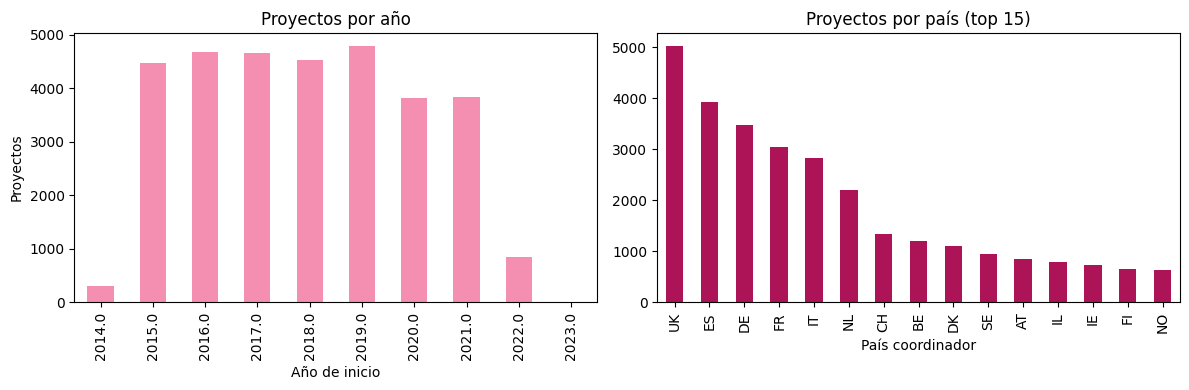

In [28]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

# Proyectos por año de inicio
datos["startDate"].dt.year.value_counts().sort_index().plot(kind="bar", ax=ejes[0], color="#f48fb1")
ejes[0].set_xlabel("Año de inicio")
ejes[0].set_ylabel("Proyectos")
ejes[0].set_title("Proyectos por año")

# Proyectos por país coordinador (los 15 primeros)
datos["coordinatorCountry"].value_counts().head(15).plot(kind="bar", ax=ejes[1], color="#ad1457")
ejes[1].set_xlabel("País coordinador")
ejes[1].set_title("Proyectos por país (top 15)")

plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "eda_anio_pais.png", dpi=120)
plt.show()

### 4.4. Análisis preliminar del texto

Para no "mirar" la validación ni el test, este análisis se hace **solo con train**.
Aquí usamos un `CountVectorizer` sencillo (minúsculas y stopwords en inglés); el preprocesado
completo (lematización, etc.) es parte del notebook de TF-IDF.

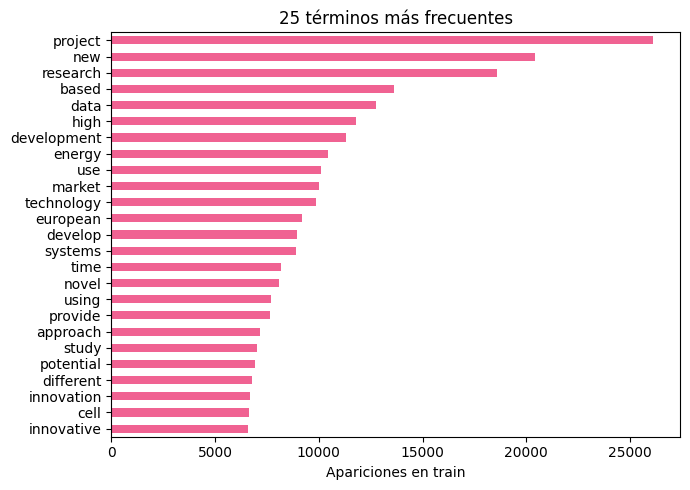

In [29]:
from sklearn.feature_extraction.text import CountVectorizer

contador = CountVectorizer(stop_words="english", token_pattern=r"[a-zA-Z]{3,}")
X_cuentas = contador.fit_transform(train["summary"])

frecuencias = pd.Series(np.asarray(X_cuentas.sum(axis=0)).ravel(),
                        index=contador.get_feature_names_out()).sort_values(ascending=False)

plt.figure(figsize=(7, 5))
frecuencias.head(25).sort_values().plot(kind="barh", color="#f06292")
plt.xlabel("Apariciones en train")
plt.title("25 términos más frecuentes")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "eda_terminos_frecuentes.png", dpi=120)
plt.show()

Muchos de los términos más frecuentes (*project*, *research*, *new*, *development*...) aparecen en casi
todos los resúmenes y no ayudan a distinguir áreas. Son las "stopwords del dominio" que menciona el
enunciado: en el TF-IDF las eliminaremos con `max_df`.

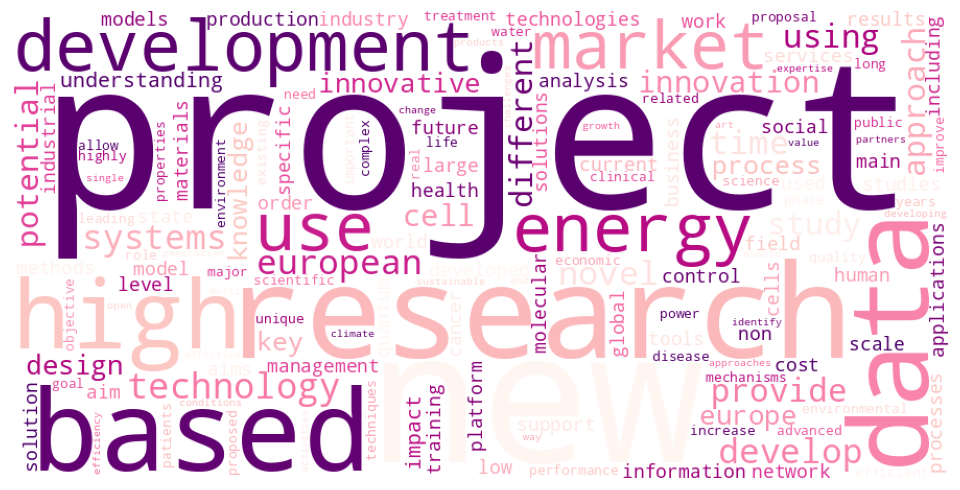

In [30]:
from wordcloud import WordCloud

# Usamos una paleta de colores rosa ('RdPu') para la nube de palabras
nube = WordCloud(width=900, height=450, background_color="white", max_words=150, colormap="RdPu")
nube.generate_from_frequencies(frecuencias.to_dict())

plt.figure(figsize=(10, 5))
plt.imshow(nube)
plt.axis("off")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "eda_nube_palabras.png", dpi=120)
plt.show()

In [23]:
# Términos más frecuentes en algunas clases: aquí sí se ve el tema de cada una
for clase in ["computer and information sciences", "basic medicine", "earth and related environmental sciences"]:
    X_clase = X_cuentas[(train["nivel2"] == clase).values]
    top = pd.Series(np.asarray(X_clase.sum(axis=0)).ravel(),
                    index=contador.get_feature_names_out()).sort_values(ascending=False)
    print(f"{clase}: {', '.join(top.head(12).index)}")

computer and information sciences: data, project, new, based, research, market, software, systems, time, development, use, technology
basic medicine: new, project, research, development, cells, disease, cell, drug, immune, clinical, patients, novel
earth and related environmental sciences: climate, project, change, research, new, data, global, based, water, european, use, knowledge


In [24]:
# Un ejemplo de resumen por clase (primeros 300 caracteres)
for clase in ["computer and information sciences", "basic medicine", "earth and related environmental sciences"]:
    ejemplo = train[train["nivel2"] == clase].iloc[0]
    print(f"--- {clase} ---")
    print(ejemplo["title"])
    print(ejemplo["summary"][:300], "...\n")

--- computer and information sciences ---
LOFAR for Space Weather
TThe LOFAR for Space Weather (LOFAR4SW) design proposal will deliver the full conceptual and technical design for creating a new leading-edge European research facility for space weather science.Space weather research is prominent in international research programmes (e.g., H2020, ESA, WMO, COSPAR), ...

--- basic medicine ---
Understanding Cerebral Malaria using 3D Blood-Brain Barrier models
Malaria is a major public health problem and it still causes more than 400,000 deaths per year. Cerebral malaria (CM) is one of the most serious complications, with 20% mortality rates even after administration of fast-acting antimalarials. CM pathology is characterized by sequestration of P. falcip ...

--- earth and related environmental sciences ---
Real Time 360 Live Streaming Electric City Auto Tours
Live Electric Tour (LET) is a unique shared experience for the new urban tourist. While you tour a modern Capital in a futuristic